# ЛР №4. Байесовская сеть

**Датасет:** UCI Adult (Census Income), выборка из переписи населения США 1994 года.

План работы
1. Импорты и настройки
2. Данные: что такое объект, какие переменные и как они могут быть связаны
3. Подготовка данных: пропуски, редкие категории, дискретизация, достаточность наблюдений
4. Вопросы к модели (формулируются до построения сети)
5. Структура сети: рёбра, их обоснование, визуализация
6. Условные вероятности: оценка параметров и разбор таблиц
7. Вероятностный вывод: ответы на вопросы
8. Эксперимент с evidence
9. Анализ структуры: удаление ребра, направление рёбер
10. Причинность
11. Итог

## 1. Импорты и настройки

In [35]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import train_test_split

from pgmpy.estimators import HillClimbSearch
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator
from pgmpy.structure_score import BIC

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_PATH = "data/adult.data"
ESS = 10

## 2. Данные

**Источник:** https://archive.ics.uci.edu/dataset/2/adult, файл `adult.data`

1 объект — 1 взрослый житель США из переписи 1994 года. При создании датасета в него отбирали только людей старше 16 лет, которые работали хотя бы 1 час в неделю

**Переменные, которые используются в сети:**

| Переменная в сети | Исходный столбец | Что означает |
|---|---|---|
| `Sex` | `sex` | пол |
| `Age` | `age` | возраст, лет |
| `Education` | `education` | высший полученный уровень образования |
| `Occupation` | `occupation` | род занятий (14 групп профессий) |
| `Hours` | `hours_per_week` | сколько часов в неделю человек обычно работает |
| `Income` | `income` | годовой доход больше 50 тыс. $ или нет |

**Какие столбцы не используются и почему:**
- `fnlwgt` — вес строки в выборке переписи (сколько людей в населении она представляет), это не характеристика человека;
- `education_num` — то же самое, что `education`, только числом;
- `relationship` (Husband / Wife / Own-child …) — почти полностью определяется полом и семейным положением, т.е. дублирует их;
- `marital_status` — сильно связан с доходом, но направление связи спорное (брак повышает доход или люди с доходом чаще женятся?), а через `Husband/Wife` переплетён с полом.
- `capital_gain`, `capital_loss` — у 92–95% людей нули; это скорее следствие богатства, чем его причина;
- `race`, `native_country` — сильный дисбаланс (85% White, 90% США) и много редких категорий;
- `workclass` (госслужба / частный сектор / самозанятый) — частично дублирует профессию.

**Какие зависимости можно ожидать**:
- возраст влияет на образование: молодые ещё учатся, а старшие поколения в среднем реже получали высшее образование;
- образование и пол влияют на профессию;
- возраст, пол и профессия влияют на то, сколько человек работает;
- образование, профессия, часы работы и возраст (стаж) влияют на доход.

In [36]:
COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education_num", "marital_status",
    "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss",
    "hours_per_week", "native_country", "income",
]
raw = pd.read_csv(DATA_PATH, header=None, names=COLUMNS, skipinitialspace=True, na_values="?")
print(raw.shape)
raw.head()

(32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 3. Подготовка данных

### 3.1. Пропущенные значения

In [37]:
na = raw.isna().sum()
print(na[na > 0])
print()
print(pd.crosstab(raw["workclass"].fillna("?"), raw["occupation"].isna().rename("occupation is NaN")))
print()
print(raw.groupby(raw["occupation"].isna().rename("occupation is NaN")).agg(
    n=("age", "size"), age_median=("age", "median"), hours_median=("hours_per_week", "median"),
    share_female=("sex", lambda s: (s == "Female").mean()),
    share_rich=("income", lambda s: (s == ">50K").mean()),
).round(3))

workclass         1836
occupation        1843
native_country     583
dtype: int64

occupation is NaN  False  True 
workclass                      
?                      0   1836
Federal-gov          960      0
Local-gov           2093      0
Never-worked           0      7
Private            22696      0
Self-emp-inc        1116      0
Self-emp-not-inc    2541      0
State-gov           1298      0
Without-pay           14      0

                       n  age_median  hours_median  share_female  share_rich
occupation is NaN                                                           
False              30718        37.0          40.0         0.323       0.249
True                1843        35.0          36.0         0.456       0.104


- `occupation` и `workclass` пропущены в одних и тех же строках: 1 836 строк с `workclass = ?` и ещё 7 с `Never-worked`. Всего 1 843 строки (5.7%).
- Восстановить профессию не из чего: единственный близкий признак (`workclass`) пропущен в тех же строках. 
- Поэтому эти строки удаляем. Это немного смещает выборку: люди без профессии - в основном молодёжь и пожилые с неполным днём, среди них больше женщин и меньше людей с доходом > 50K (10% против 25%). После удаления сеть описывает работающих людей с известной профессией.
- `native_country` в сети не используется, так что его пропуски нам не мешают.

### 3.2. Редкие категории

In [38]:
for col in ["education", "occupation", "race", "native_country", "marital_status"]:
    vc = raw[col].value_counts(dropna=False)
    print(f"{col}: {len(vc)} значений; самые редкие:", vc.tail(4).to_dict())
print()
print("доля White:", round((raw["race"] == "White").mean(), 3),
      "| доля United-States:", round((raw["native_country"] == "United-States").mean(), 3))
print("доля нулей capital_gain:", round((raw["capital_gain"] == 0).mean(), 3),
      "| capital_loss:", round((raw["capital_loss"] == 0).mean(), 3))

education: 16 значений; самые редкие: {'Doctorate': 413, '5th-6th': 333, '1st-4th': 168, 'Preschool': 51}
occupation: 15 значений; самые редкие: {'Tech-support': 928, 'Protective-serv': 649, 'Priv-house-serv': 149, 'Armed-Forces': 9}
race: 5 значений; самые редкие: {'Black': 3124, 'Asian-Pac-Islander': 1039, 'Amer-Indian-Eskimo': 311, 'Other': 271}
native_country: 42 значений; самые редкие: {'Honduras': 13, 'Hungary': 13, 'Scotland': 12, 'Holand-Netherlands': 1}
marital_status: 7 значений; самые редкие: {'Separated': 1025, 'Widowed': 993, 'Married-spouse-absent': 418, 'Married-AF-spouse': 23}

доля White: 0.854 | доля United-States: 0.896
доля нулей capital_gain: 0.917 | capital_loss: 0.953


- `education` — 16 уровней, некоторые очень редкие. Отдельные классы школы (`9th`, `10th`, `11th`) с точки зрения дохода почти ничем не отличаются. Группируем по полученной ступени образования в 5 состояний:
  - `NoHS` — школа не окончена;
  - `HS` — окончена школа;
  - `College` — колледж без степени бакалавра;
  - `Bachelors` — бакалавр;
  - `Advanced` — степень выше бакалавра (Masters, Prof-school, Doctorate).
- `occupation` — 14 значений. Группируем по типу работы в 4 состояния:
  - `Manual` — ручной труд (Craft-repair, Machine-op-inspct, Transport-moving, Handlers-cleaners, Farming-fishing);
  - `Service` — сфера услуг (Other-service, Priv-house-serv, Protective-serv);
  - `Office_Sales` — офис и продажи (Adm-clerical, Sales, Tech-support);
  - `Prof_Mgmt` — специалисты и руководители (Prof-specialty, Exec-managerial).
- `Armed-Forces` — всего 9 человек. По такому числу ничего нельзя оценить, и ни в одну группу они по смыслу не подходят, поэтому их удаляем.

### 3.3. Дискретизация непрерывных признаков

Байесовская сеть в `pgmpy` работает с дискретными переменными, поэтому `age` и `hours_per_week` нужно разбить на интервалы. 

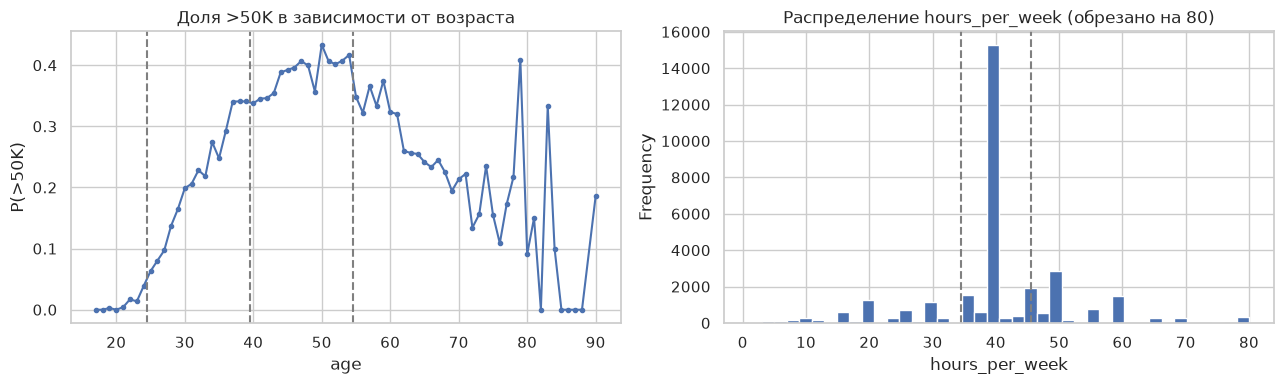

{40: 15217, 50: 2819, 45: 1824, 60: 1475, 35: 1297, 20: 1224}


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

age_rate = raw.groupby("age")["income"].apply(lambda s: (s == ">50K").mean())
axes[0].plot(age_rate.index, age_rate.values, marker=".")
for b in [24.5, 39.5, 54.5]:
    axes[0].axvline(b, color="grey", ls="--")
axes[0].set(title="Доля >50K в зависимости от возраста", xlabel="age", ylabel="P(>50K)")

raw["hours_per_week"].clip(upper=80).plot.hist(bins=40, ax=axes[1])
for b in [34.5, 45.5]:
    axes[1].axvline(b, color="grey", ls="--")
axes[1].set(title="Распределение hours_per_week (обрезано на 80)", xlabel="hours_per_week")
plt.tight_layout()
plt.show()

print(raw["hours_per_week"].value_counts().head(6).to_dict())

Age - 4 группы, примерно соответствующие этапам жизни:
- `17-24` — Доход > 50K здесь почти не встречается (около 1%);
- `25-39` — доля > 50K быстро растёт;
- `40-54` — пик дохода;
- `55+` — предпенсионный и пенсионный возраст, доход снижается.

Hours - 3 группы. Ровно 40 часов в неделю работает почти половина людей, поэтому равные по ширине интервалы не подходят.
- `<35` — неполная занятость;
- `35-45` — стандартная рабочая неделя
- `>45` — переработки.

In [40]:
EDU_MAP = {
    **{k: "NoHS" for k in ["Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th"]},
    "HS-grad": "HS",
    "Some-college": "College", "Assoc-voc": "College", "Assoc-acdm": "College",
    "Bachelors": "Bachelors",
    "Masters": "Advanced", "Prof-school": "Advanced", "Doctorate": "Advanced",
}
OCC_MAP = {
    "Craft-repair": "Manual", "Machine-op-inspct": "Manual", "Transport-moving": "Manual",
    "Handlers-cleaners": "Manual", "Farming-fishing": "Manual",
    "Other-service": "Service", "Priv-house-serv": "Service", "Protective-serv": "Service",
    "Adm-clerical": "Office_Sales", "Sales": "Office_Sales", "Tech-support": "Office_Sales",
    "Exec-managerial": "Prof_Mgmt", "Prof-specialty": "Prof_Mgmt",
}
STATES = {
    "Sex": ["Female", "Male"],
    "Age": ["17-24", "25-39", "40-54", "55+"],
    "Education": ["NoHS", "HS", "College", "Bachelors", "Advanced"],
    "Occupation": ["Manual", "Service", "Office_Sales", "Prof_Mgmt"],
    "Hours": ["<35", "35-45", ">45"],
    "Income": ["<=50K", ">50K"],
}

clean = raw[raw["occupation"].notna() & (raw["occupation"] != "Armed-Forces")]
print(f"удалено строк: {len(raw) - len(clean)} ({(len(raw) - len(clean)) / len(raw):.1%})")

data = pd.DataFrame({
    "Sex": clean["sex"],
    "Age": pd.cut(clean["age"], [16, 24, 39, 54, 90], labels=STATES["Age"]).astype(str),
    "Education": clean["education"].map(EDU_MAP),
    "Occupation": clean["occupation"].map(OCC_MAP),
    "Hours": pd.cut(clean["hours_per_week"], [0, 34, 45, 99], labels=STATES["Hours"]).astype(str),
    "Income": clean["income"],
}).reset_index(drop=True)

assert data.notna().all().all()
for col, states in STATES.items():
    assert set(data[col]) == set(states), col
print(data.shape)
data.head()

удалено строк: 1852 (5.7%)
(30709, 6)


,Sex,Age,Education,Occupation,Hours,Income
0,Male,25-39,Bachelors,Office_Sales,35-45,<=50K
1,Male,40-54,Bachelors,Prof_Mgmt,<35,<=50K
2,Male,25-39,HS,Manual,35-45,<=50K
3,Male,40-54,NoHS,Manual,35-45,<=50K
4,Female,25-39,Bachelors,Prof_Mgmt,35-45,<=50K


### 3.4. Число состояний и достаточность наблюдений

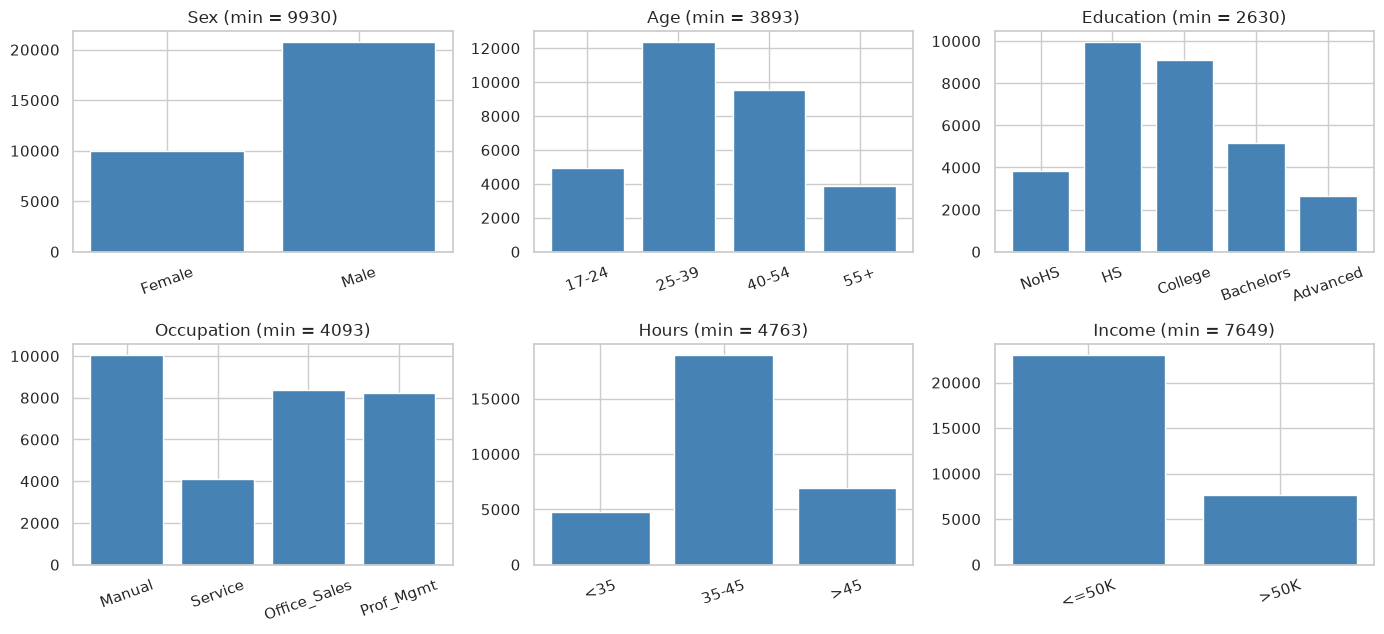

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, (col, states) in zip(axes.ravel(), STATES.items()):
    vc = data[col].value_counts().reindex(states)
    ax.bar(states, vc.values, color="steelblue")
    ax.set_title(f"{col} (min = {vc.min()})")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [42]:
# Самая большая таблица - P(Income | Age, Sex, Education, Occupation, Hours)
income_parents = ["Age", "Sex", "Education", "Occupation", "Hours"]
n_combos = np.prod([len(STATES[p]) for p in income_parents])
cell_counts = data.groupby(income_parents).size().reindex(
    pd.MultiIndex.from_product([STATES[p] for p in income_parents]), fill_value=0
)
print("комбинаций родителей:", n_combos)
print("пустых комбинаций:", (cell_counts == 0).sum())
print("комбинаций с < 10 наблюдениями:", (cell_counts < 10).sum(),
      f"- в них {cell_counts[cell_counts < 10].sum()} строк ({cell_counts[cell_counts < 10].sum() / len(data):.1%} данных)")
print("медиана наблюдений на комбинацию:", int(cell_counts.median()))

комбинаций родителей: 480
пустых комбинаций: 26
комбинаций с < 10 наблюдениями: 151 - в них 527 строк (1.7% данных)
медиана наблюдений на комбинацию: 21


У каждой переменной от 2 до 5 состояний, самое маленькое состояние содержит 2 630 наблюдений (`Education = Advanced`).

Самая большая таблица — `P(Income | Age, Sex, Education, Occupation, Hours)`: у неё 4·2·5·4·3 = 480 комбинаций родителей. 

Большее число родителей у `Income` (например, если добавить семейное положение) сделало бы таблицу слишком разреженной. Это ещё одна причина держать граф компактным.

## 4. Вопросы к модели

1. Насколько знание об образовании меняет вероятность дохода > 50K: P(>50K) против P(>50K | Education)? И важно ли образование, если профессия уже известна: P(>50K | Occupation) против P(>50K | Occupation, Education)?
2. Разрыв между мужчинами и женщинами. Насколько отличаются P(>50K | Female) и P(>50K | Male)? Сохраняется ли разница, если сравнивать людей с одинаковой профессией и часами работы (а также образованием и возрастом)?
3. Известно, что человек зарабатывает > 50K. Что тогда можно сказать о его образовании и возрасте: P(Education | >50K) против P(Education)?
4. Насколько вероятно, что сотрудник офиса или продаж — женщина: P(Female | Office_Sales)? Как изменится эта вероятность, если дополнительно известно его образование: P(Female | Office_Sales, Bachelors)?

## 5. Структура сети


`Sex, Age  →  Education  →  Occupation  →  Hours  →  Income`


| Ребро | Почему есть зависимость | Почему такое направление |
|---|---|---|
| Age → Education | люди 17–24 лет ещё не успели получить степень; старшие поколения реже учились в вузах | образование не может изменить возраст |
| Sex → Occupation | профессиональная сегрегация 1994 г.: женщины чаще работают в офисе и сфере услуг, мужчины — на ручной работе | пол задан от рождения |
| Education → Occupation | для многих профессий (врач, юрист, инженер) нужен диплом | образование получают до работы |
| Age → Hours | молодые совмещают работу с учёбой, пожилые переходят на неполный день | возраст не зависит от графика |
| Sex → Hours | женщины чаще работают неполный день (уход за детьми и домом) | пол задан от рождения |
| Occupation → Hours | у руководителей переработки норма, в сфере услуг много частичной занятости | график определяется работой, а не наоборот |
| Age → Income | стаж и опыт повышают зарплату | возраст не зависит от дохода |
| Education → Income | квалификацию оплачивают выше даже внутри одной группы профессий | образование получено до дохода |
| Occupation → Income | у разных профессий разный уровень оплаты | доход — результат работы |
| Hours → Income | доход годовой, при почасовой оплате больше часов — больше денег | доход складывается из отработанного времени |
| Sex → Income | разрыв в оплате при одинаковых профессии и часах. | пол задан от рождения |

Ребро Sex → Income самое спорное, поэтому именно его мы удалим в разделе 9.

**Какие рёбра не добавлены:**
- Sex → Education. Среди работающих в 1994 г. уровень образования мужчин и женщин почти одинаковый (проверка ниже);
- Age → Occupation считаем, что возраст влияет на профессию через образование.
- Education → Hours. Считаем, что образование влияет на график только через профессию;
- Sex - Age. Причинной связи между полом и возрастом нет.

In [43]:
EDGES = [
    ("Age", "Education"),
    ("Sex", "Occupation"),
    ("Education", "Occupation"),
    ("Age", "Hours"),
    ("Sex", "Hours"),
    ("Occupation", "Hours"),
    ("Age", "Income"),
    ("Education", "Income"),
    ("Occupation", "Income"),
    ("Hours", "Income"),
    ("Sex", "Income"),
]
dag = DiscreteBayesianNetwork(EDGES)
print("узлов:", len(dag.nodes()), "| рёбер:", len(dag.edges()))
print("это DAG:", nx.is_directed_acyclic_graph(nx.DiGraph(dag.edges())))

узлов: 6 | рёбер: 11
это DAG: True


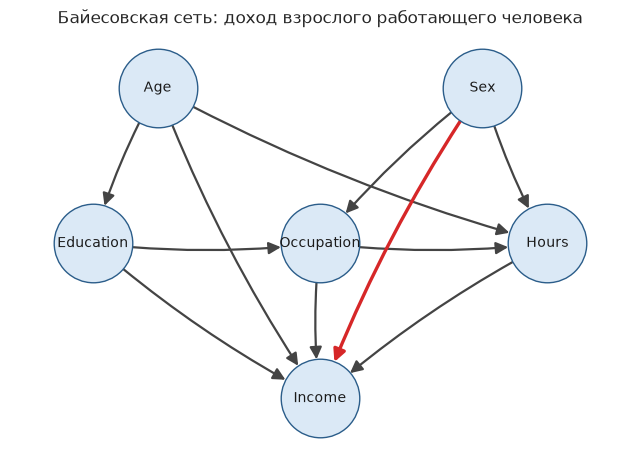

In [44]:
POS = {
    "Age": (0.0, 2.0), "Sex": (3.0, 2.0),
    "Education": (-0.6, 1.0), "Occupation": (1.5, 1.0), "Hours": (3.6, 1.0),
    "Income": (1.5, 0.0),
}

def draw_dag(edges, title, highlight=(), removed=(), ax=None):
    g = nx.DiGraph(edges)
    g.add_nodes_from(POS)
    ax = ax or plt.subplots(figsize=(8, 5.5))[1]
    nx.draw_networkx_nodes(g, POS, node_size=3200, node_color="#dbe9f6", edgecolors="#2b5d8a", ax=ax)
    nx.draw_networkx_labels(g, POS, font_size=10, ax=ax)
    normal = [e for e in g.edges() if e not in highlight]
    nx.draw_networkx_edges(g, POS, edgelist=normal, node_size=3200, arrowsize=18, width=1.6,
                           edge_color="#444", connectionstyle="arc3,rad=0.06", ax=ax)
    if highlight:
        nx.draw_networkx_edges(g, POS, edgelist=list(highlight), node_size=3200, arrowsize=18, width=2.4,
                               edge_color="#d62728", connectionstyle="arc3,rad=0.06", ax=ax)
    if removed:
        nx.draw_networkx_edges(nx.DiGraph(list(removed)), POS, edgelist=list(removed), node_size=3200,
                               arrowsize=18, width=1.6, style="dashed", edge_color="#bbb",
                               connectionstyle="arc3,rad=0.06", ax=ax)
    ax.set_title(title)
    ax.margins(0.12)
    ax.axis("off")
    return ax

draw_dag(EDGES, "Байесовская сеть: доход взрослого работающего человека", highlight=[("Sex", "Income")])
plt.show()

Красным выделено остаточное ребр

### 5.1. Проверка независимостей, которые следуют из графа

Пол и возраст - корни графа, а у `Education` единственный родитель - `Age`. Значит, по структуре сети Sex ⟂ Age и Sex ⟂ Education. Проверим, насколько это согласуется с данными. Для силы связи используем Cramers V: 0 — связи нет, 1 — полная зависимость.

In [45]:
def cramers_v(a, b):
    t = pd.crosstab(data[a], data[b])
    chi2 = chi2_contingency(t)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

print("Независимости, которые следуют из графа (d-разделение):")
for a, b in [("Sex", "Age"), ("Sex", "Education")]:
    print(f"  {a} ⟂ {b}:  dag.is_dconnected = {dag.is_dconnected(a, b)},  Cramers V в данных = {cramers_v(a, b):.3f}")
print("Для сравнения - пары, связанные ребром:")
for a, b in [("Age", "Education"), ("Sex", "Occupation"), ("Education", "Occupation"), ("Occupation", "Income")]:
    print(f"  {a} - {b}:  Cramers V = {cramers_v(a, b):.3f}")

Независимости, которые следуют из графа (d-разделение):
  Sex ⟂ Age:  dag.is_dconnected = False,  Cramers V в данных = 0.112
  Sex ⟂ Education:  dag.is_dconnected = False,  Cramers V в данных = 0.075
Для сравнения - пары, связанные ребром:
  Age - Education:  Cramers V = 0.141
  Sex - Occupation:  Cramers V = 0.352
  Education - Occupation:  Cramers V = 0.353
  Occupation - Income:  Cramers V = 0.316


In [46]:
share_f = data.groupby("Age")["Sex"].apply(lambda s: (s == "Female").mean()).reindex(STATES["Age"])
print("Доля женщин в датасете по возрастным группам:")
print(share_f.round(3).to_dict())

Доля женщин в датасете по возрастным группам:
{'17-24': 0.442, '25-39': 0.31, '40-54': 0.29, '55+': 0.298}


1. Sex — Education: V = 0.075, связь очень слабая
2. Sex — Age: V = 0.112, т.е. в данных связь есть: среди 17–24-летних женщин 44%, а во всех старших группах — 29–31%. Ребро всё равно не добавляем: пол не может влиять на возраст, и наоборот. Эта зависимость появилась из-за того, как отбирали данные. В датасет попали только работающие люди. 

## 6. Условные вероятности

Оцениваем все CPD по данным.

In [47]:
def fit_bn(edges, df=data, ess=ESS):
    model = DiscreteBayesianNetwork(edges)
    model.add_nodes_from(STATES)
    est = DiscreteBayesianEstimator(state_names=STATES, prior_type="BDeu", equivalent_sample_size=ess)
    return model.fit(df, estimator=est)

model = fit_bn(EDGES)
infer = VariableElimination(model)
assert model.check_model()
for cpd in model.get_cpds():
    print(f"P({cpd.variable} | {', '.join(cpd.variables[1:]) or '-'}):  "
          f"таблица {cpd.get_values().shape[0]} x {cpd.get_values().shape[1]}")

P(Age | -):  таблица 4 x 1
P(Education | Age):  таблица 5 x 4
P(Sex | -):  таблица 2 x 1
P(Occupation | Education, Sex):  таблица 4 x 10
P(Hours | Age, Occupation, Sex):  таблица 3 x 32
P(Income | Age, Education, Hours, Occupation, Sex):  таблица 2 x 480


In [48]:
def cpd_frame(model, var):
    """CPD в виде DataFrame: строки - состояния var, столбцы - комбинации родителей."""
    cpd = model.get_cpds(var)
    parents = cpd.variables[1:]
    if parents:
        cols = pd.MultiIndex.from_product([cpd.state_names[p] for p in parents], names=parents)
    else:
        cols = ["P"]
    return pd.DataFrame(cpd.get_values(), index=pd.Index(cpd.state_names[var], name=var), columns=cols)


def query(var, evidence=None, inf=None):
    """Апостериорное распределение var при evidence (через Variable Elimination)."""
    inf = inf or infer
    f = inf.query([var], evidence=evidence or {}, show_progress=False)
    return pd.Series(f.values, index=f.state_names[var]).reindex(STATES[var])


def empirical(var, evidence=None, df=data):
    """Частоты var в подвыборке, где выполнено evidence; плюс размер подвыборки."""
    sub = df
    for k, v in (evidence or {}).items():
        sub = sub[sub[k] == v]
    return sub[var].value_counts(normalize=True).reindex(STATES[var], fill_value=0.0), len(sub)


def p_rich(evidence=None, inf=None):
    return query("Income", evidence, inf)[">50K"]

### 6.1. P(Education | Age)

In [49]:
cpd_edu = cpd_frame(model, "Education")
emp_edu = pd.crosstab(data["Education"], data["Age"], normalize="columns").reindex(index=STATES["Education"], columns=STATES["Age"])
print("P(Education | Age) из сети:")
display(cpd_edu.round(3))
print("Максимальное расхождение с частотами в данных:", f"{(cpd_edu.values - emp_edu.values).__abs__().max():.4f}")

P(Education | Age) из сети:


Age,17-24,25-39,40-54,55+
Education,,,,
NoHS,0.206,0.093,0.094,0.195
HS,0.303,0.338,0.313,0.337
College,0.394,0.295,0.281,0.217
Bachelors,0.093,0.202,0.178,0.135
Advanced,0.005,0.072,0.134,0.116


Максимальное расхождение с частотами в данных: 0.0001


- Значения почти совпадают с частотами в данных (расхождение < 0.001): клеток всего 20, и в каждой тысячи наблюдений, так что априорное распределение почти не влияет.
- Неожиданный результат: у людей 55+ уровень образования ниже, чем у 40–54-летних (NoHS 19.5% против 9.4%), хотя у старших было больше времени, чтобы учиться. `Age` здесь - это ещё и поколение. Люди, родившиеся до 1940 года, реже заканчивали школу и вуз. Так что связь Age → Education отражает в основном различия между поколениями, а не то, что с возрастом люди теряют образование.
- У 17–24 лет почти нет `Advanced` (0.5%) и мало `Bachelors`: они просто ещё не успели доучиться. Зато у них самая большая доля `College`, т.е. многие сейчас учатся.

### 6.2. P(Occupation | Sex, Education)

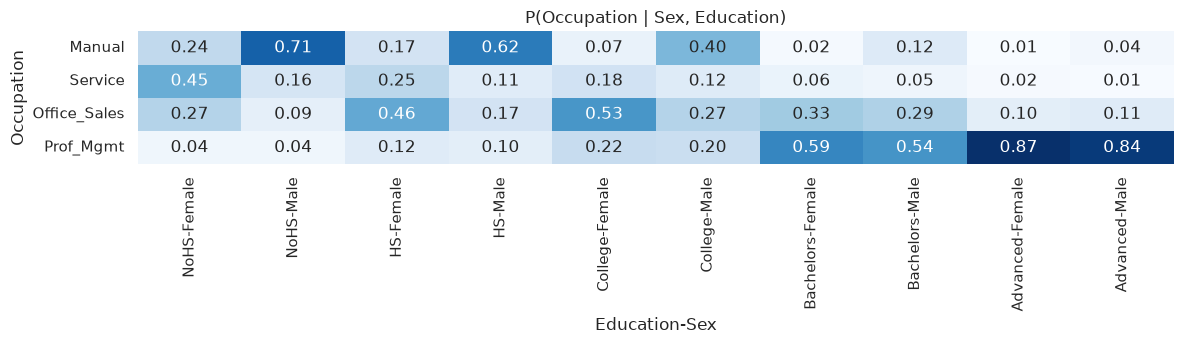

In [50]:
cpd_occ = cpd_frame(model, "Occupation")
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(cpd_occ, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax)
ax.set_title("P(Occupation | Sex, Education)")
plt.tight_layout()
plt.show()

- Образование сильнее всего определяет профессию: при `Advanced` 84–87% людей - специалисты и руководители, при `NoHS` таких около 4%.
- Пол меняет профессию даже при одинаковом образовании. У женщин с `HS` или `College` самое частое состояние — `Office_Sales` (46–53%; в 1994 г. это секретари, клерки, кассиры), а у мужчин с тем же образованием — `Manual` (40–62%). Без школьного аттестата женщины чаще всего работают в сфере услуг (45%), а мужчины — на ручной работе (71%). Это и есть сегрегация, ради которой проведено ребро Sex → Occupation.

### 6.3. P(Hours | Age, Sex, Occupation)

In [ ]:
cpd_hours = cpd_frame(model, "Hours")
sl = cpd_hours.xs("Office_Sales", axis=1, level="Occupation")
print("P(Hours | Age, Sex, Occupation = Office_Sales):")
display(sl.round(3))

P(Hours | Age, Sex, Occupation = Office_Sales):


Age    17-24         25-39         40-54           55+       
Sex   Female   Male Female   Male Female   Male Female   Male
Hours                                                        
<35    0.531  0.392  0.136  0.065  0.129  0.049  0.328  0.201
35-45  0.430  0.490  0.762  0.616  0.767  0.602  0.605  0.573
>45    0.040  0.118  0.102  0.319  0.104  0.349  0.067  0.226

Показан срез для `Office_Sales` (в полной таблице 32 столбца).
- Влияние возраста выглядит как буква U: неполный день чаще всего у 17–24 лет (совмещают с учёбой) и у людей 55+.
- При одинаковых возрасте и профессии женщины в 2–3 раза чаще работают меньше 35 часов, а мужчины — в 3 раза чаще больше 45. Это согласуется с ожиданиями о распределении обязанностей в семье.

### 6.4. P(Income | ·)

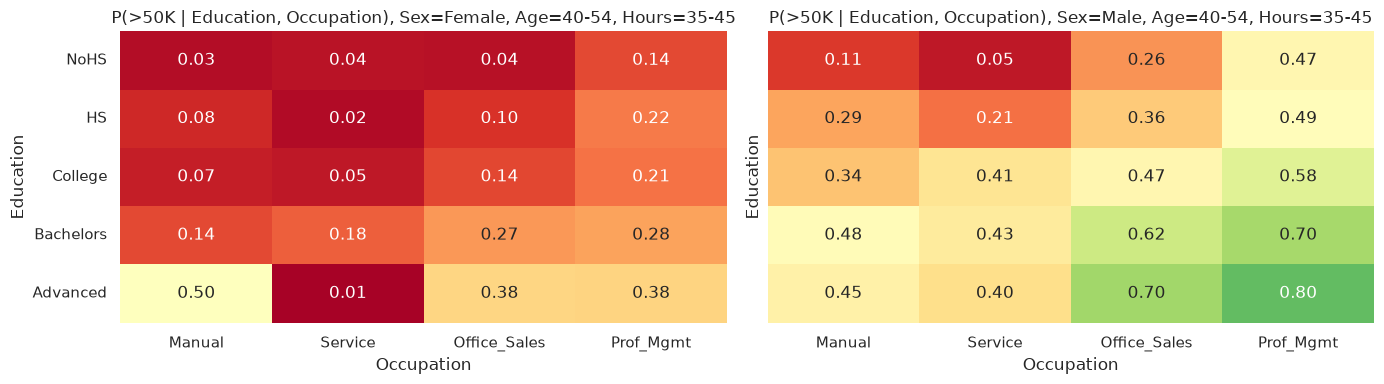

Female, 40-54, 35-45, Advanced, Manual: n = 2, из них >50K: 1
Female, 40-54, 35-45, Advanced, Service: n = 2, из них >50K: 0


In [52]:
cpd_inc = cpd_frame(model, "Income").loc[">50K"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, sex in zip(axes, STATES["Sex"]):
    tab = cpd_inc.xs((sex, "35-45"), level=("Sex", "Hours")).xs("40-54", level="Age").unstack("Occupation")
    tab = tab.reindex(index=STATES["Education"], columns=STATES["Occupation"])
    sns.heatmap(tab, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, cbar=False, ax=ax)
    ax.set_title(f"P(>50K | Education, Occupation), Sex={sex}, Age=40-54, Hours=35-45")
plt.tight_layout()
plt.show()

# Подозрительные клетки - сколько за ними наблюдений?
for occ in ["Manual", "Service"]:
    ev = {"Sex": "Female", "Age": "40-54", "Hours": "35-45", "Education": "Advanced", "Occupation": occ}
    emp, n = empirical("Income", ev)
    print(f"Female, 40-54, 35-45, Advanced, {occ}: n = {n}, из них >50K: {int(round(emp['>50K'] * n))}")

На тепловых картах  P(>50K) для людей 40–54 лет со стандартным графиком.
- Неожиданно большой разрыв по полу. В той же профессии, с теми же образованием, возрастом и часами у женщин вероятность в 2–3 раза ниже (например, Bachelors + Prof_Mgmt: 0.28 против 0.70).
- у женщин `Advanced + Manual = 0.50` и `Advanced + Service = 0.01`. Под каждой из них всего 2 наблюдения: в первой 1 из 2 человек зарабатывает > 50K, во второй — 0 из 2. Это шум оценки по нескольким наблюдениям: при таком n BDeu почти не сглаживает, и мы видим частоту по двум людям. Интерпретировать такие клетки нельзя.

Грубая группа `Prof_Mgmt` объединяет разные профессии, и между полами есть и другие различия:

In [53]:
# Почему внутри Prof_Mgmt у женщин доля >50K намного ниже? Посмотрим на исходные профессии
pm = clean[clean["occupation"].isin(["Exec-managerial", "Prof-specialty"])]
print("Доля Exec-managerial внутри Prof_Mgmt:")
print(pm.groupby("sex")["occupation"].apply(lambda s: (s == "Exec-managerial").mean()).round(3))
print()
print("Доля >50K внутри Prof_Mgmt, по полу и семейному положению (relationship):")
print(pm.pivot_table(index="relationship", columns="sex", values="income",
                     aggfunc=lambda s: (s == ">50K").mean()).round(3))

Доля Exec-managerial внутри Prof_Mgmt:
sex
Female    0.433
Male      0.525
Name: occupation, dtype: float64

Доля >50K внутри Prof_Mgmt, по полу и семейному положению (relationship):
sex             Female   Male
relationship                 
Husband            NaN  0.697
Not-in-family    0.166  0.277
Other-relative   0.125  0.200
Own-child        0.037  0.051
Unmarried        0.114  0.392
Wife             0.703  1.000


1. Внутри `Prof_Mgmt` женщины реже работают руководителями (43% против 52%) и чаще — специалистами с более низкой оплатой: учителя и медсёстры относятся к `Prof-specialty`. Наша группировка этого не видит.
2. Огромную роль играет семейное положение, которого нет в сети. Внутри `Prof_Mgmt` у мужей доля > 50K равна 0.70, у мужчин, живущих отдельно от семьи (`Not-in-family`), - 0.28. 

### 6.5. Насколько сеть в целом согласуется с данными

обучим сеть на 80% данных и посмотрим, насколько хорошо P(Income | остальные переменные) предсказывает доход на оставшихся 20%. 

In [ ]:
train, test = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE, stratify=data["Income"])
y_test = (test["Income"] == ">50K").astype(int)

def holdout_scores(edges):
    m = fit_bn(edges, df=train)
    p = m.predict_probability(test.drop(columns="Income"))["Income_>50K"].values
    return log_loss(y_test, p), roc_auc_score(y_test, p)

p_const = np.full(len(test), (train["Income"] == ">50K").mean())
print(f"константа P(>50K) = {p_const[0]:.3f}: log-loss = {log_loss(y_test, p_const):.4f}, ROC-AUC = 0.5")
ll, auc = holdout_scores(EDGES)
print(f"байесовская сеть:            log-loss = {ll:.4f}, ROC-AUC = {auc:.4f}")

константа P(>50K) = 0.249: log-loss = 0.5613, ROC-AUC = 0.5
байесовская сеть:            log-loss = 0.4292, ROC-AUC = 0.8289



log-loss — штраф за вероятностные прогнозы, чем меньше, тем лучше. Особенно сильно штрафует уверенные ошибки. Подходит, потому что сеть выдаёт именно вероятности.
ROC-AUC — насколько хорошо модель ранжирует людей. Если взять случайного богатого и случайного небогатого, AUC — это вероятность, что богатому сеть даст более высокую оценку. 0.5 — угадывание, 1 — идеал.

## 7. Вероятностный вывод: ответы на вопросы

«сеть» - ответ, полученный выводом; «данные» - доля в подвыборке с таким же evidence; n - размер этой подвыборки.

### Вопрос 1. Образование и доход

In [55]:
rows = []
for ev in [{}, {"Education": "HS"}, {"Education": "Bachelors"}, {"Education": "Advanced"},
           {"Occupation": "Prof_Mgmt"}, {"Occupation": "Prof_Mgmt", "Education": "Bachelors"},
           {"Occupation": "Prof_Mgmt", "Education": "Advanced"}]:
    emp, n = empirical("Income", ev)
    rows.append({"evidence": ev or "—", "сеть P(>50K|e)": p_rich(ev), "данные": emp[">50K"], "n": n})
q1 = pd.DataFrame(rows)
q1

,evidence,сеть P(>50K|e),данные,n
0,—,0.243,0.249,30709
1,{'Education': 'HS'},0.161,0.163,9964
2,{'Education': 'Bachelors'},0.403,0.420,5181
3,{'Education': 'Advanced'},0.602,0.627,2630
4,{'Occupation': 'Prof_Mgmt'},0.436,0.466,8206
5,"{'Occupation': 'Prof_Mgmt', 'Education': 'Bach...",0.450,0.474,2864
6,"{'Occupation': 'Prof_Mgmt', 'Education': 'Adva...",0.626,0.656,2225


1. Без информации P(>50K) = 0.243.
2. + образование: `HS` - 0.16, `Bachelors` - 0.40, `Advanced` - 0.60.
3. Если профессия уже известна, бакалавриат почти ничего не добавляет: P(>50K | Prof_Mgmt) = 0.436, а с `Bachelors` - 0.450. А вот `Advanced` и при известной профессии даёт большой прирост (0.626). Это прямое ребро Education → Income: среди специалистов и руководителей люди с учёной или профессиональной степенью (врачи, юристы) зарабатывают заметно больше.

Для `Prof_Mgmt` сеть даёт 0.436, а в данных 0.466. Причина - отсутствующее ребро Age → Occupation:

In [ ]:
# Почему сеть недооценивает P(>50K | Prof_Mgmt)?
pd.DataFrame({
    "сеть P(Age | Prof_Mgmt)": query("Age", {"Occupation": "Prof_Mgmt"}),
    "данные": empirical("Age", {"Occupation": "Prof_Mgmt"})[0],
}).round(3)

,сеть P(Age | Prof_Mgmt),данные
17-24,0.107,0.064
25-39,0.413,0.403
40-54,0.356,0.392
55+,0.124,0.140


В нашей сети возраст влияет на профессию только через образование, поэтому сеть считает, что молодёжи среди специалистов и руководителей столько, сколько положено по образованию: 10.7% людей 17–24 лет (в данных 6.4%) и 35.6% людей 40–54 лет (в данных 39.2%). В реальности руководителями становятся с опытом. Так как молодые почти не получают > 50K, сеть немного занижает вероятность. 

### Вопрос 2. Разрыв между мужчинами и женщинами

In [57]:
rows = []
for ev in [{}, {"Sex": "Female"}, {"Sex": "Male"},
           {"Sex": "Female", "Occupation": "Prof_Mgmt", "Hours": "35-45"},
           {"Sex": "Male", "Occupation": "Prof_Mgmt", "Hours": "35-45"},
           {"Sex": "Female", "Occupation": "Prof_Mgmt", "Hours": "35-45", "Education": "Bachelors", "Age": "40-54"},
           {"Sex": "Male", "Occupation": "Prof_Mgmt", "Hours": "35-45", "Education": "Bachelors", "Age": "40-54"}]:
    emp, n = empirical("Income", ev)
    rows.append({"evidence": ev or "—", "сеть P(>50K|e)": p_rich(ev), "данные": emp[">50K"], "n": n})
q2 = pd.DataFrame(rows)
q2

,evidence,сеть P(>50K|e),данные,n
0,—,0.243,0.249,30709
1,{'Sex': 'Female'},0.123,0.113,9930
2,{'Sex': 'Male'},0.300,0.314,20779
3,"{'Sex': 'Female', 'Occupation': 'Prof_Mgmt', '...",0.232,0.219,1734
4,"{'Sex': 'Male', 'Occupation': 'Prof_Mgmt', 'Ho...",0.512,0.551,2985
5,"{'Sex': 'Female', 'Occupation': 'Prof_Mgmt', '...",0.282,0.282,149
6,"{'Sex': 'Male', 'Occupation': 'Prof_Mgmt', 'Ho...",0.695,0.695,430


1. Без условий P(>50K | Female) = 0.12, P(>50K | Male) = 0.30
2. При одинаковой профессии и часах (`Prof_Mgmt`, 35–45 ч) разрыв не исчезает: 0.23 против 0.51.
3. Если ещё одинаковы образование и возраст (бакалавр, 40–54 лет): 0.28 против 0.70. 
4. Вывод: профессия и часы объясняют лишь небольшую часть разрыва, а основная его часть проходит по прямому ребру Sex → Income.

### Вопрос 3. Что известно о человеке с доходом > 50K (обратный вывод)

In [58]:
q3 = pd.DataFrame({
    "P(Education)": query("Education"),
    "P(Education | >50K)": query("Education", {"Income": ">50K"}),
    "P(Education | <=50K)": query("Education", {"Income": "<=50K"}),
})
q3["данные | >50K"] = empirical("Education", {"Income": ">50K"})[0]
display(q3.round(3))

q3_age = pd.DataFrame({
    "P(Age)": query("Age"),
    "P(Age | >50K)": query("Age", {"Income": ">50K"}),
    "данные | >50K": empirical("Age", {"Income": ">50K"})[0],
})
display(q3_age.round(3))

,P(Education),P(Education | >50K),P(Education | <=50K),данные | >50K
NoHS,0.124,0.031,0.154,0.031
HS,0.324,0.215,0.360,0.213
College,0.297,0.262,0.308,0.256
Bachelors,0.169,0.280,0.133,0.284
Advanced,0.086,0.212,0.045,0.216


,P(Age),P(Age | >50K),данные | >50K
17-24,0.161,0.010,0.008
25-39,0.403,0.366,0.357
40-54,0.310,0.474,0.481
55+,0.127,0.150,0.155



- Среди людей с доходом > 50K доля `Advanced` вырастает с 8.6% до 21%, доля `Bachelors` — с 17% до 28%. Доля людей без школьного аттестата падает в 4 раза (12% → 3%). Больше половины людей с высоким доходом имеют как минимум степень бакалавра
-  доля 17–24 лет падает с 16% до 1%. Больше всего вырастает группа 40–54 лет (31% → 47%), что согласуется с пиком дохода на графике из раздела 3.
- Расхождение с данными не больше 0.01.

### Вопрос 4. Пол сотрудника офиса и его образование

In [59]:
rows = []
for ev in [{}, {"Occupation": "Office_Sales"}, {"Occupation": "Office_Sales", "Education": "Bachelors"},
           {"Occupation": "Office_Sales", "Education": "NoHS"},
           {"Education": "Bachelors"}]:
    emp, n = empirical("Sex", ev)
    rows.append({"evidence": ev or "—", "сеть P(Female|e)": query("Sex", ev)["Female"], "данные": emp["Female"], "n": n})
q4 = pd.DataFrame(rows)
q4

,evidence,сеть P(Female|e),данные,n
0,—,0.323,0.323,30709
1,{'Occupation': 'Office_Sales'},0.486,0.497,8348
2,"{'Occupation': 'Office_Sales', 'Education': 'B...",0.352,0.327,1545
3,"{'Occupation': 'Office_Sales', 'Education': 'N...",0.593,0.565,549
4,{'Education': 'Bachelors'},0.323,0.300,5181


- Без информации P(Female) = 0.32.
- Если человек работает в офисе или продажах, P(Female) = 0.49
- Если дополнительно известно, что у него бакалавриат, P(Female) падает до 0.35. Если же у него нет школьного аттестата, P(Female) растёт до 0.59.
- При этом само по себе образование ничего не говорит о поле: P(Female | Bachelors) = 0.323 = P(Female).

Это коллайдер Sex → Occupation ← Education. Пол и образование - 2 независимые причины профессии. Пока профессия неизвестна, они независимы. Когда профессия становится известна, они начинают конкурировать как объяснения. 

Данные подтверждают эффект (0.497 → 0.327 и 0.565). Небольшое расхождение для P(Female | Bachelors) (сеть 0.323, данные 0.300) — это цена допущения Sex ⟂ Education (V = 0.075, см. 5.1).

## 8. Эксперимент с evidence

Целевая переменная - `Income`. Последовательно добавляем сведения о человеке: образование → возраст → профессия → часы → пол.

In [60]:
STEPS = [
    ("ничего не известно", {}),
    ("+ Education=Bachelors", {"Education": "Bachelors"}),
    ("+ Age=40-54", {"Age": "40-54"}),
    ("+ Occupation=Prof_Mgmt", {"Occupation": "Prof_Mgmt"}),
    ("+ Hours=>45", {"Hours": ">45"}),
    ("+ Sex=Female", {"Sex": "Female"}),
]

rows, ev = [], {}
for label, add in STEPS:
    ev = {**ev, **add}
    post = query("Income", ev)
    emp, n = empirical("Income", ev)
    rows.append({"шаг": label, "P(>50K)": post[">50K"], "данные": emp[">50K"], "n": n})
evid = pd.DataFrame(rows)
evid["изменение"] = evid["P(>50K)"].diff()
display(evid)

# Тот же путь, но последний шаг - Sex=Male
ev_male = {**ev, "Sex": "Male"}
print(f"для сравнения, последний шаг Sex=Male: P(>50K) = {p_rich(ev_male):.3f}, "
      f"данные = {empirical('Income', ev_male)[0]['>50K']:.3f} (n = {empirical('Income', ev_male)[1]})")

,шаг,P(>50K),данные,n,изменение
0,ничего не известно,0.243,0.249,30709,NaN
1,+ Education=Bachelors,0.403,0.420,5181,0.161
2,+ Age=40-54,0.531,0.565,1697,0.128
3,+ Occupation=Prof_Mgmt,0.572,0.609,975,0.041
4,+ Hours=>45,0.672,0.688,349,0.100
5,+ Sex=Female,0.403,0.403,62,-0.269


для сравнения, последний шаг Sex=Male: P(>50K) = 0.749, данные = 0.749 (n = 287)


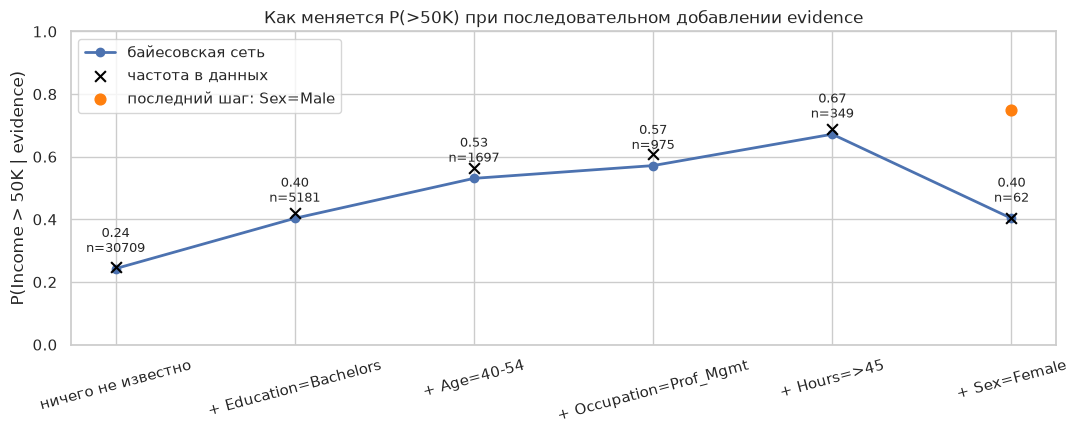

In [61]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(evid))
ax.plot(x, evid["P(>50K)"], marker="o", lw=2, label="байесовская сеть")
ax.scatter(x, evid["данные"], color="black", marker="x", s=60, zorder=3, label="частота в данных")
for xi, (p, n) in enumerate(zip(evid["P(>50K)"], evid["n"])):
    ax.annotate(f"{p:.2f}\nn={n}", (xi, p), textcoords="offset points", xytext=(0, 12), ha="center", fontsize=9)
ax.scatter([x[-1]], [p_rich(ev_male)], color="tab:orange", s=60, zorder=3, label="последний шаг: Sex=Male")
ax.set_xticks(x, evid["шаг"], rotation=15)
ax.set_ylim(0, 1)
ax.set_ylabel("P(Income > 50K | evidence)")
ax.set_title("Как меняется P(>50K) при последовательном добавлении evidence")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

1. Education = Bachelors (+0.16). Образование действует на доход напрямую (Education → Income) и через профессию (Education → Occupation → Income).
2. Age = 40-54 (+0.13). Путь Age → Education больше ничего не добавляет: образование уже известно.
3. Occupation = Prof_Mgmt (+0.04). Из бакалавр и так следовало, что человек скорее всего специалист или руководитель.
4. Hours = >45 (+0.10). Переработки повышают годовой доход.
5. Sex = Female (−0.27: с 0.67 до 0.40). Если бы последним шагом был `Male`, вероятность выросла бы до 0.75.

После последнего шага известны все родители `Income`. Так как у `Income` нет детей, никакая другая информация больше не изменит ответ. Сеть просто возвращает клетку CPT, и она совпадает с частотой в данных.

**Тот же набор evidence в другом порядке:**

In [ ]:
ORDER2 = ["Sex", "Hours", "Occupation", "Age", "Education"]
full_ev = {"Sex": "Female", "Education": "Bachelors", "Age": "40-54", "Occupation": "Prof_Mgmt", "Hours": ">45"}
rows, ev2 = [{"шаг": "ничего не известно", "P(>50K)": p_rich({})}], {}
for k in ORDER2:
    ev2[k] = full_ev[k]
    rows.append({"шаг": f"+ {k}={full_ev[k]}", "P(>50K)": p_rich(ev2)})
evid2 = pd.DataFrame(rows)
evid2["изменение"] = evid2["P(>50K)"].diff()
evid2

,шаг,P(>50K),изменение
0,ничего не известно,0.243,NaN
1,+ Sex=Female,0.123,-0.120
2,+ Hours=>45,0.222,0.099
3,+ Occupation=Prof_Mgmt,0.351,0.129
4,+ Age=40-54,0.393,0.042
5,+ Education=Bachelors,0.403,0.010


- Итоговая вероятность та же (0.403)
- А вот вклад каждой переменной зависит от того, что уже известно. Образование, добавленное первым, давало +0.16, а добавленное последним - всего +0.01.

**Вторая цепочка: целевая переменная `Education`**

,NoHS,HS,College,Bachelors,Advanced
ничего не известно,0.124,0.324,0.297,0.169,0.086
+ Income=>50K,0.031,0.215,0.262,0.280,0.212
+ Occupation=Prof_Mgmt,0.008,0.079,0.162,0.361,0.390
+ Age=17-24,0.112,0.237,0.170,0.417,0.064


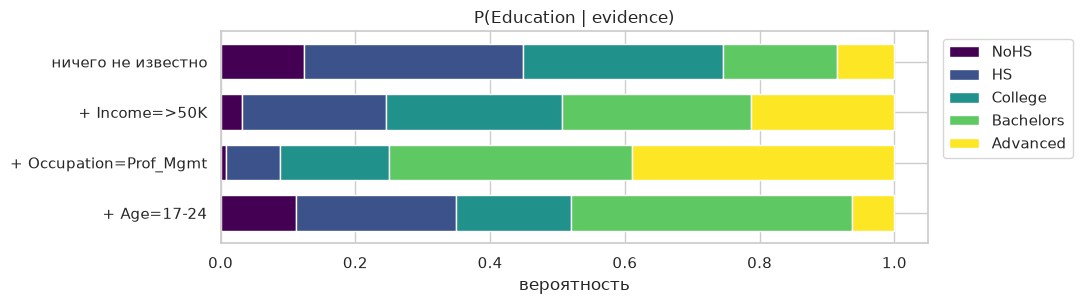

In [ ]:
rows, ev3 = [], {}
for label, add in [("ничего не известно", {}), ("+ Income=>50K", {"Income": ">50K"}),
                   ("+ Occupation=Prof_Mgmt", {"Occupation": "Prof_Mgmt"}),
                   ("+ Age=17-24", {"Age": "17-24"})]:
    ev3 = {**ev3, **add}
    rows.append(query("Education", ev3).rename(label))
edu_chain = pd.DataFrame(rows)
display(edu_chain.round(3))

edu_chain.plot.barh(stacked=True, figsize=(11, 3.2), colormap="viridis", width=0.7)
plt.gca().invert_yaxis()
plt.xlabel("вероятность")
plt.title("P(Education | evidence)")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

- Income > 50K. Распределение сдвигается к высоким ступеням: доля Bachelors + Advanced растёт с 26% до 49%.
- Occupation = Prof_Mgmt. Bachelors + Advanced = 75%: у образования есть ещё одно наблюдаемое следствие, и оно указывает в ту же сторону.
- Age = 17-24. Доля `Advanced` падает с 39% до 6%, а доля `Bachelors` растёт до 42%. 

## 9. Анализ структуры

### 9.1. Удаляем ребро Sex → Income



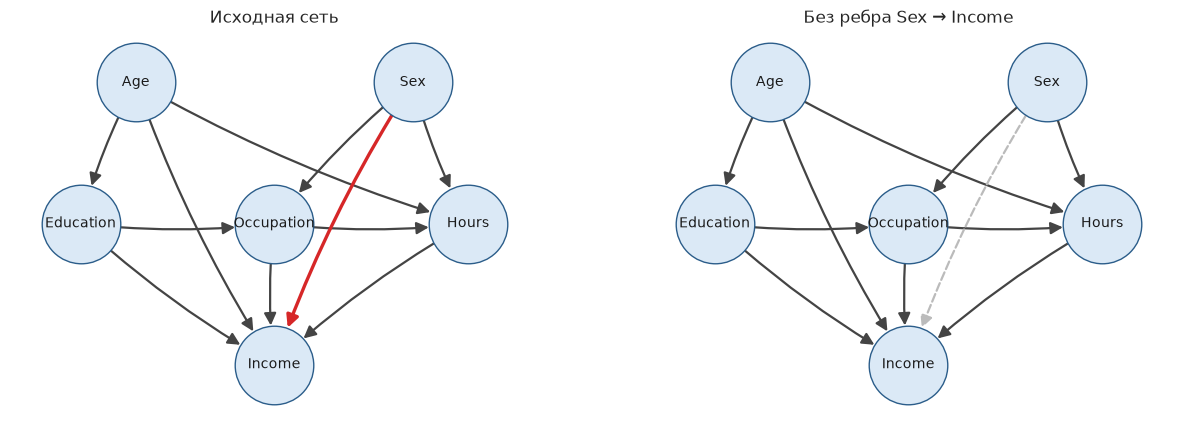

,evidence,исходная сеть,без Sex→Income,данные,n
0,—,0.243,0.247,0.249,30709
1,{'Sex': 'Female'},0.123,0.225,0.113,9930
2,{'Sex': 'Male'},0.300,0.257,0.314,20779
3,"{'Sex': 'Female', 'Occupation': 'Prof_Mgmt', '...",0.232,0.419,0.219,1734
4,"{'Sex': 'Male', 'Occupation': 'Prof_Mgmt', 'Ho...",0.512,0.419,0.551,2985
5,"{'Sex': 'Female', 'Occupation': 'Prof_Mgmt', '...",0.282,0.589,0.282,149
6,"{'Sex': 'Male', 'Occupation': 'Prof_Mgmt', 'Ho...",0.695,0.589,0.695,430


In [64]:
EDGES_NO_SEX_INC = [e for e in EDGES if e != ("Sex", "Income")]
model_no = fit_bn(EDGES_NO_SEX_INC)
infer_no = VariableElimination(model_no)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
draw_dag(EDGES, "Исходная сеть", highlight=[("Sex", "Income")], ax=axes[0])
draw_dag(EDGES_NO_SEX_INC, "Без ребра Sex → Income", removed=[("Sex", "Income")], ax=axes[1])
plt.show()

rows = []
for ev in q2["evidence"]:
    ev = ev if isinstance(ev, dict) else {}
    emp, n = empirical("Income", ev)
    rows.append({"evidence": ev or "—", "исходная сеть": p_rich(ev), "без Sex→Income": p_rich(ev, infer_no),
                 "данные": emp[">50K"], "n": n})
cmp_struct = pd.DataFrame(rows)
cmp_struct


- Без ребра P(>50K | Female) = 0.225 вместо 0.123, P(>50K | Male) = 0.257 вместо 0.300. Разрыв сократился с 18 до 3 процентных пунктов, хотя в данных он 20 п.п.
- При одинаковых профессии и часах сеть без ребра даёт почти одинаковый ответ для мужчин и женщин: 0.4193 и 0.4195 (в данных 0.219 и 0.551). Если известны ещё образование и возраст, ответы совпадают точно: 0.589 и 0.589.
- Общая вероятность P(>50K) почти не изменилась (0.243 → 0.247), т.е. удаление ребра искажает ответы при условиях, но не среднее.


In [65]:
bic = BIC(data)
ll_no, auc_no = holdout_scores(EDGES_NO_SEX_INC)
pd.DataFrame({
    "BIC (весь датасет, больше = лучше)": [bic.score(DiscreteBayesianNetwork(EDGES)), bic.score(DiscreteBayesianNetwork(EDGES_NO_SEX_INC))],
    "log-loss на test": [ll, ll_no],
    "ROC-AUC на test": [auc, auc_no],
    "параметров в P(Income|·)": [len(cpd_frame(model, "Income").columns), len(cpd_frame(model_no, "Income").columns)],
}, index=["исходная сеть", "без Sex→Income"])

,"BIC (весь датасет, больше = лучше)",log-loss на test,ROC-AUC на test,параметров в P(Income|·)
исходная сеть,-177659.302,0.429,0.829,480
без Sex→Income,-177196.393,0.443,0.807,240



- **BIC** (оценка того, насколько структура соответствует данным, со штрафом за число параметров) предпочитает сеть без ребра. Ребро удваивает таблицу `P(Income | ·)` (+240 параметров). Штраф BIC - примерно log(N)/2 ≈ 5.2 за параметр, т.е. около 1 250 очков, и это больше выигрыша в правдоподобии.

BIC обрадовался что стало дешевле на 240 параметров

### 9.2. Насколько уверенно можно выбирать направление рёбер по данным

Возьмём два разворота рёбер:
- Age → Education ⇒ Education → Age. Ни одна v-структура не появляется и не исчезает. 
- Sex → Occupation ⇒ Occupation → Sex. Исчезает v-структура Sex → Occupation ← Education.

Для точности сравнения сети здесь обучаются почти без априорного распределения (ESS → 0).

In [66]:
# 1) Разворот Age → Education на Education → Age: v-структуры не меняются → эквивалентный по Маркову граф
EDGES_REV = [("Education", "Age") if e == ("Age", "Education") else e for e in EDGES]
# 2) Разворот Sex → Occupation на Occupation → Sex: разрушает v-структуру Sex → Occupation ← Education
EDGES_V = [("Occupation", "Sex") if e == ("Sex", "Occupation") else e for e in EDGES]

rows = []
for name, edges in [("исходная", EDGES), ("Education → Age", EDGES_REV), ("Occupation → Sex", EDGES_V)]:
    inf = VariableElimination(fit_bn(edges, ess=1e-6))  # почти MLE, чтобы сравнение было точным
    rows.append({
        "структура": name,
        "BIC": bic.score(DiscreteBayesianNetwork(edges)),
        "P(>50K | Education=Advanced)": p_rich({"Education": "Advanced"}, inf),
        "P(Female)": query("Sex", inf=inf)["Female"],
        "P(Female | Education=Advanced)": query("Sex", {"Education": "Advanced"}, inf)["Female"],
    })
pd.DataFrame(rows).set_index("структура")

,BIC,P(>50K | Education=Advanced),P(Female),P(Female | Education=Advanced)
структура,,,,
исходная,-177659.302,0.602,0.323,0.323
Education → Age,-177659.302,0.602,0.323,0.323
Occupation → Sex,-177744.887,0.595,0.323,0.341


- **Разворот Age → Education** даёт точно такой же BIC и такие же ответы на запросы. 
- **Разворот Sex → Occupation** меняет набор независимостей. BIC стал хуже, а сеть теперь считает пол и образование зависимыми

Посмотрим, какую структуру найдёт алгоритм, который ищет граф только по данным (HillClimbSearch, максимизирует BIC):

Рёбра, найденные HillClimbSearch (BIC):
         Age → Hours       (есть в нашей сети)
   Education → Age         (есть, но в обратную сторону)
   Education → Income      (есть в нашей сети)
   Education → Occupation  (есть в нашей сети)
   Education → Sex         (нет в нашей сети)
       Hours → Sex         (есть, но в обратную сторону)
      Income → Age         (есть, но в обратную сторону)
      Income → Hours       (есть, но в обратную сторону)
      Income → Occupation  (есть, но в обратную сторону)
      Income → Sex         (есть, но в обратную сторону)
         Sex → Occupation  (есть в нашей сети)

Наши рёбра, которых нет у HillClimb (ни в какую сторону): [('Occupation', 'Hours')]
BIC: наша сеть = -177659, HillClimb = -175605


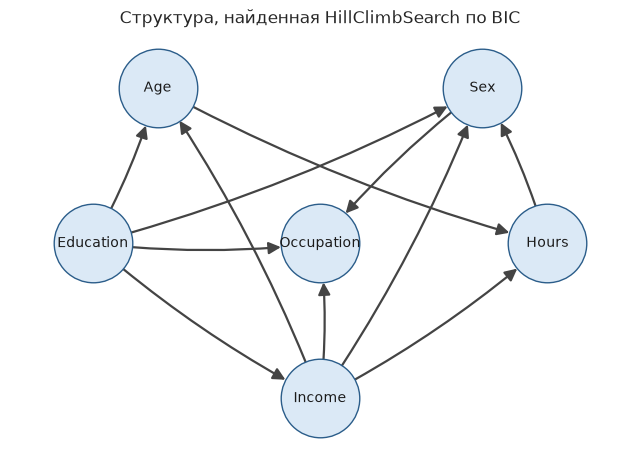

In [67]:
hc_dag = HillClimbSearch(data).estimate(scoring_method="bic-d", show_progress=False)
hc_edges = sorted(hc_dag.edges())
print("Рёбра, найденные HillClimbSearch (BIC):")
for e in hc_edges:
    mark = "есть в нашей сети" if e in EDGES else ("есть, но в обратную сторону" if e[::-1] in EDGES else "нет в нашей сети")
    print(f"  {e[0]:>10} → {e[1]:<10}  ({mark})")
print("\nНаши рёбра, которых нет у HillClimb (ни в какую сторону):",
      [e for e in EDGES if e not in hc_edges and e[::-1] not in hc_edges])
print(f"BIC: наша сеть = {bic.score(DiscreteBayesianNetwork(EDGES)):.0f}, HillClimb = {bic.score(DiscreteBayesianNetwork(hc_edges)):.0f}")

draw_dag(hc_edges, "Структура, найденная HillClimbSearch по BIC")
plt.show()

- Алгоритм нашёл граф с лучшим BIC, чем у нас. В основном за счёт меньшего числа параметров: у него нет таблицы с 5 родителями.
- Но многие его стрелки бессмысленны как причинные связи: `Income → Sex`, `Income → Age`, `Hours → Sex`, `Education → Sex`.
- Совпадает с нашей сетью то, что связи вообще есть: почти все пары, соединённые у нас, соединены и у алгоритма. Это подтверждает, что наличие связей выбрано разумно.

Вывод: по наблюдаемым данным можно довольно надёжно установить, какие переменные связаны. 

## 10. Причинность

Сеть нельзя считать причинной моделью Это модель совместного распределения: она корректно отвечает на вопросы вида «что мы ожидаем увидеть, если наблюдаем X». Но не на вопросы «что произойдёт, если изменить* X». 


Если бы граф был причинным и полным (без скрытых конфаундеров), эффект вмешательства P(>50K | do(X = x)) можно было бы вычислить по формуле корректировки (backdoor adjustment). Сравним его с обычным условием:

In [68]:
from pgmpy.inference import CausalInference

ci = CausalInference(model)
rows = []
for var, val in [("Education", "Bachelors"), ("Education", "Advanced"), ("Occupation", "Prof_Mgmt"), ("Hours", ">45")]:
    f = ci.query(["Income"], do={var: val}, show_progress=False)
    rows.append({
        "переменная": f"{var}={val}",
        "наблюдение P(>50K | X=x)": p_rich({var: val}),
        "вмешательство P(>50K | do(X=x))": float(f.values[f.state_names["Income"].index(">50K")]),
    })
do_tab = pd.DataFrame(rows).set_index("переменная")
do_tab["разница"] = do_tab.iloc[:, 0] - do_tab.iloc[:, 1]
do_tab

,наблюдение P(>50K | X=x),вмешательство P(>50K | do(X=x)),разница
переменная,,,
Education=Bachelors,0.403,0.378,0.025
Education=Advanced,0.602,0.510,0.091
Occupation=Prof_Mgmt,0.436,0.336,0.101
Hours=>45,0.399,0.304,0.095


## 11. Итог

**Что удалось узнать с помощью сети:**
- Сеть из 6 переменных и 11 рёбер хорошо воспроизводит данные: ответы на запросы отличаются от частот в подвыборках на 0.00–0.03, а на отложенной выборке ROC-AUC = 0.83.
- Образование — сильнейший фактор: P(>50K) равна 0.16 для выпускника школы, 0.40 для бакалавра и 0.60 для степени выше бакалавра. При этом при известной профессии бакалавриат почти ничего не добавляет: его влияние идёт в основном через профессию.
- У человека с доходом > 50K почти наверняка есть хотя бы школьный аттестат (97%), и он почти никогда не младше 25 лет (1%).

**Самые интересные зависимости:**
- **Разрыв в доходах между полами** (0.12 против 0.30) почти не объясняется профессией и часами. Он остаётся при одинаковых профессии, часах, образовании и возрасте (0.28 против 0.70). Значительная его часть, по-видимому, связана с семейным положением и тонкими различиями профессий, которых нет в модели.
- **Explaining away** в v-структуре Sex → Occupation ← Education. Сами по себе пол и образование независимы, но для офисного сотрудника знание о дипломе меняет вероятность того, что это женщина (0.49 → 0.35).
- **Эффект поколений** в P(Education | Age): у людей 55+ образование ниже, чем у 40–54-летних.

**Как evidence влияет на вероятности:**
- Каждый новый факт сдвигает распределение в соответствии с открытыми путями графа. Итог не зависит от порядка фактов, но вклад каждого факта зависит от уже известного: образование давало +0.16, если его узнать первым, и +0.01 — если последним.
- После того как известны все родители `Income`, другие переменные на него уже не влияют.

**Насколько результаты зависят от структуры:**
- Очень сильно. Удаление одного ребра Sex → Income превращает 20-процентный разрыв в 3-процентный, а при известных профессии и часах разрыв в модели практически исчезает (0.4193 против 0.4195).
- Отсутствие ребра Age → Occupation заметно занижает P(>50K | Prof_Mgmt).
- По данным можно установить, **какие** переменные связаны, но не направление большинства рёбер. Эквивалентные по Маркову графы неразличимы, а алгоритм поиска структуры рисует стрелки вроде `Income → Sex`.

**Ограничения модели:**
- Выборка 1994 года и только работающие люди с известной профессией. На население в целом и на сегодняшний день выводы не переносятся; отбор порождает ложные связи (Sex — Age).
- Нет важных переменных: семейного положения, конкретной профессии, отрасли, региона, способностей. Их влияние «размазано» по имеющимся рёбрам, особенно по Sex → Income.
- Дискретизация теряет информацию: внутри `Prof_Mgmt` и `>45` объединены очень разные люди, а доход — это только бинарный порог 50K.
- Таблица P(Income | ·) с 480 комбинациями родителей частично разреженная. Для редких сочетаний оценки ненадёжны (раздел 6.4).
- Модель не причинная: она отвечает на вопросы о наблюдениях, а не о вмешательствах.